# CT or T? Predicting Who Wins the Round
**CS:GO Round Winner Prediction using Machine Learning**



## Short Forms

| Short form | Full form / meaning |
|---|---|
| **CS:GO** | Counter-Strike: Global Offensive |
| **CT** | Counter-Terrorists (defenders) |
| **T** | Terrorists (attackers) |
| **ct_ / t_** | Column prefix for CT team / T team (e.g. `ct_health`, `t_money`) |
| **diff** | Difference, CT minus T (e.g. `armor_diff`) |
| **round_id** | Round number reconstructed from `time_left`, used for leakage-free splitting |
| **EDA** | Exploratory Data Analysis |
| **CV** | Cross-Validation |
| **LogReg** | Logistic Regression |
| **DT** | Decision Tree |
| **RF** | Random Forest |
| **XGB** | XGBoost (eXtreme Gradient Boosting) |
| **LGBM** | LightGBM (Light Gradient Boosting Machine) |
| **ROC** | Receiver Operating Characteristic |
| **AUC** | Area Under the ROC Curve |
| **ANOVA** | Analysis of Variance |
| **TP / TN / FP / FN** | True Positive / True Negative / False Positive / False Negative |
| **Sensitivity** | TP / (TP + FN): CT rounds correctly predicted |
| **Specificity** | TN / (TN + FP): T rounds correctly predicted |

# Part 1: Data Loading, Understanding and Cleaning


### Load Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

RANDOM_STATE = 42   # shob jaigay same seed, jate result repeat kora jay

uploaded = files.upload()   # csgo_round_snapshots.csv select koro
df = pd.read_csv('csgo_round_snapshots.csv')

print("Shape:", df.shape)
df.head()

Saving csgo_round_snapshots.csv to csgo_round_snapshots.csv
Shape: (122410, 97)


,time_left,ct_score,t_score,map,bomb_planted,ct_health,t_health,ct_armor,t_armor,ct_money,...,t_grenade_flashbang,ct_grenade_smokegrenade,t_grenade_smokegrenade,ct_grenade_incendiarygrenade,t_grenade_incendiarygrenade,ct_grenade_molotovgrenade,t_grenade_molotovgrenade,ct_grenade_decoygrenade,t_grenade_decoygrenade,round_winner
0,175.00,0.0,0.0,de_dust2,False,500.0,500.0,0.0,0.0,4000.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CT
1,156.03,0.0,0.0,de_dust2,False,500.0,500.0,400.0,300.0,600.0,...,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,CT
2,96.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,...,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,CT
3,76.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CT
4,174.97,1.0,0.0,de_dust2,False,500.0,500.0,192.0,0.0,18350.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CT


Data Overview

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122410 entries, 0 to 122409
Data columns (total 97 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   time_left                     122410 non-null  float64
 1   ct_score                      122410 non-null  float64
 2   t_score                       122410 non-null  float64
 3   map                           122410 non-null  object 
 4   bomb_planted                  122410 non-null  bool   
 5   ct_health                     122410 non-null  float64
 6   t_health                      122410 non-null  float64
 7   ct_armor                      122410 non-null  float64
 8   t_armor                       122410 non-null  float64
 9   ct_money                      122410 non-null  float64
 10  t_money                       122410 non-null  float64
 11  ct_helmets                    122410 non-null  float64
 12  t_helmets                     122410 non-nul

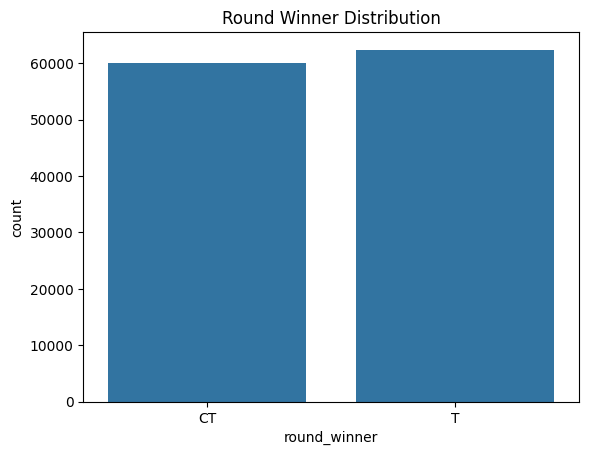

In [ ]:
# Column ar data type
df.info()

# Missing value ache kina
print("Total missing values:", df.isnull().sum())

# Duplicate row
print("Duplicate rows:", df.duplicated().sum())

# Target (round_winner) er distribution
print(df['round_winner'].value_counts(normalize=True))

sns.countplot(x='round_winner', data=df)
plt.title('Round Winner Distribution')
plt.show()

CT Win Rate by Map

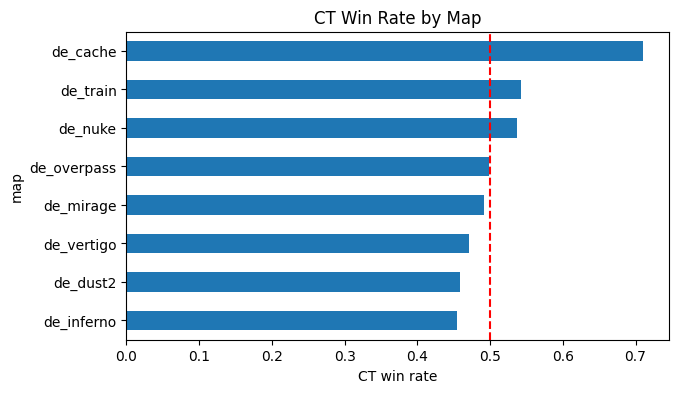

In [ ]:
map_win = (df.assign(ct_win=(df['round_winner'] == 'CT').astype(int))
             .groupby('map')['ct_win'].mean()
             .sort_values())

map_win.plot(kind='barh', figsize=(7, 4))
plt.axvline(0.5, color='red', linestyle='--')
plt.xlabel('CT win rate')
plt.title('CT Win Rate by Map')
plt.show()


Create Round ID

In [ ]:
# Round ID banano: time_left jokhon age er row er cheye beshi hoy, notun round shuru
df['round_id'] = (df['time_left'] > df['time_left'].shift(1)).cumsum()

print("Approximate number of rounds:", df['round_id'].nunique())
print("Average snapshots per round:", round(len(df) / df['round_id'].nunique(), 2))

Approximate number of rounds: 23537
Average snapshots per round: 5.2


Remove Duplicates and Encode

In [ ]:
# Duplicate remove (round_id bad diye check kora hocche)
cols = [c for c in df.columns if c != 'round_id']
before = len(df)
df = df.drop_duplicates(subset=cols).reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows, now {len(df)} rows")

# Bool ke 0/1 banano
df['bomb_planted'] = df['bomb_planted'].astype(int)

# Target ke 0/1 banano: CT = 1, T = 0
df['target'] = (df['round_winner'] == 'CT').astype(int)

Removed 4962 duplicate rows, now 117448 rows


Sanity Checks

In [ ]:
# Map koyta, prottek map e koyta row
print(df['map'].value_counts())

# Players alive 0 theke 5 er moddhe ache kina
print(df[['ct_players_alive', 't_players_alive']].describe().loc[['min', 'max']])

# time_left er range
print(df['time_left'].describe())

# Bomb planted hole CT ar T er win rate
print(df.groupby('bomb_planted')['target'].mean())

map
de_inferno     22982
de_dust2       21252
de_nuke        18078
de_mirage      17793
de_overpass    13474
de_train       12919
de_vertigo     10805
de_cache         145
Name: count, dtype: int64
     ct_players_alive  t_players_alive
min               0.0              0.0
max               5.0              6.0
count    117448.000000
mean         94.648097
std          53.224518
min           0.010000
25%          54.910000
50%          94.890000
75%         114.960000
max         175.000000
Name: time_left, dtype: float64
bomb_planted
0    0.524334
1    0.226542
Name: target, dtype: float64


Remove Invalid Rows

In [ ]:
# t_players_alive > 5 koyta row
bad = df['t_players_alive'] > 5
print("Rows with more than 5 T players alive:", bad.sum())

# Remove
df = df[~bad].reset_index(drop=True)
print("Rows now:", len(df))

Rows with more than 5 T players alive: 1
Rows now: 117447


# Part 2: Feature Engineering and Model Comparison


Feature Engineering

In [ ]:
# 1. Difference features (CT - T)
df['alive_diff']   = df['ct_players_alive'] - df['t_players_alive']
df['health_diff']  = df['ct_health'] - df['t_health']
df['armor_diff']   = df['ct_armor'] - df['t_armor']
df['money_diff']   = df['ct_money'] - df['t_money']
df['helmet_diff']  = df['ct_helmets'] - df['t_helmets']
df['score_diff']   = df['ct_score'] - df['t_score']

# 2. Per-player average health (0 alive hole 0 dhorbo)
df['ct_avg_health'] = np.where(df['ct_players_alive'] > 0,
                               df['ct_health'] / df['ct_players_alive'], 0)
df['t_avg_health']  = np.where(df['t_players_alive'] > 0,
                               df['t_health'] / df['t_players_alive'], 0)

# 3. Weapon groups
rifles = ['ak47', 'm4a1s', 'm4a4', 'aug', 'sg553', 'famas', 'galilar']
snipers = ['awp', 'ssg08', 'scar20', 'g3sg1']
for team in ['ct', 't']:
    df[f'{team}_rifles']  = df[[f'{team}_weapon_{w}' for w in rifles]].sum(axis=1)
    df[f'{team}_snipers'] = df[[f'{team}_weapon_{w}' for w in snipers]].sum(axis=1)

# 4. Total grenades
grenades = ['hegrenade', 'flashbang', 'smokegrenade',
            'incendiarygrenade', 'molotovgrenade', 'decoygrenade']
for team in ['ct', 't']:
    df[f'{team}_grenades'] = df[[f'{team}_grenade_{g}' for g in grenades]].sum(axis=1)

df['rifle_diff']   = df['ct_rifles'] - df['t_rifles']
df['grenade_diff'] = df['ct_grenades'] - df['t_grenades']

print("Shape after feature engineering:", df.shape)

Shape after feature engineering: (117447, 115)


Correlation with Target

bomb_planted    -0.191130
t_avg_health    -0.034006
ct_avg_health    0.051055
time_left        0.071911
score_diff       0.100124
money_diff       0.206099
grenade_diff     0.356890
health_diff      0.407536
alive_diff       0.423055
helmet_diff      0.473376
rifle_diff       0.486787
armor_diff       0.544046
Name: target, dtype: float64


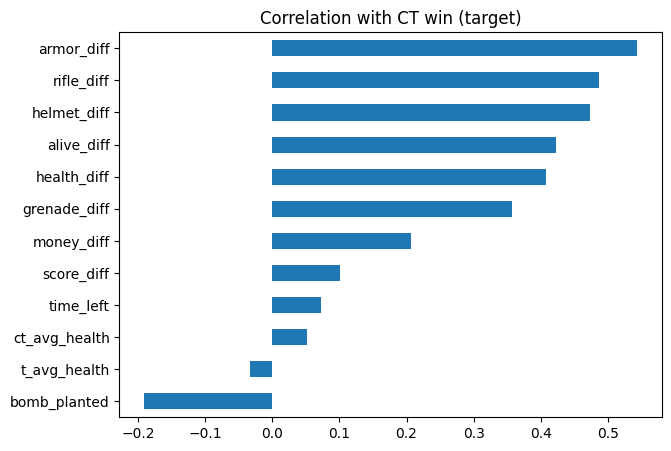

In [ ]:
new_feats = ['alive_diff', 'health_diff', 'armor_diff', 'money_diff', 'helmet_diff',
             'score_diff', 'ct_avg_health', 't_avg_health', 'rifle_diff', 'grenade_diff',
             'bomb_planted', 'time_left']

corr = df[new_feats + ['target']].corr()['target'].drop('target').sort_values()
print(corr)

corr.plot(kind='barh', figsize=(7, 5))
plt.title('Correlation with CT win (target)')
plt.show()

Train/Test Split and Baseline (Logistic Regression)

In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

# 1. Map ke one-hot
df_model = pd.get_dummies(df, columns=['map'], dtype=int)
map_cols = [c for c in df_model.columns if c.startswith('map_')]

# 2. Feature set gulo
engineered = ['alive_diff', 'health_diff', 'armor_diff', 'money_diff', 'helmet_diff',
              'score_diff', 'ct_avg_health', 't_avg_health',
              'ct_rifles', 't_rifles', 'ct_snipers', 't_snipers',
              'ct_grenades', 't_grenades', 'rifle_diff', 'grenade_diff']
drop_cols = ['round_winner', 'target', 'round_id']

raw_cols = [c for c in df_model.columns
            if c not in drop_cols + engineered]          # original + map one-hot
all_cols = raw_cols + engineered                          # original + engineered

print("Raw features:", len(raw_cols), "| With engineered:", len(all_cols))

# 3. Round ID diye split (80/20)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(df_model, df_model['target'],
                                     groups=df_model['round_id']))

train_rounds = set(df_model.loc[train_idx, 'round_id'])
test_rounds  = set(df_model.loc[test_idx, 'round_id'])
print("Overlapping rounds:", len(train_rounds & test_rounds))   # 0 howa uchit
print("Train:", len(train_idx), "| Test:", len(test_idx))

y_train = df_model.loc[train_idx, 'target']
y_test  = df_model.loc[test_idx, 'target']

# 4. Baseline function
def run_baseline(cols, name):
    X_train = df_model.loc[train_idx, cols]
    X_test  = df_model.loc[test_idx, cols]

    scaler = StandardScaler().fit(X_train)       # shudhu train e fit
    X_train_s = scaler.transform(X_train)
    X_test_s  = scaler.transform(X_test)

    model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    model.fit(X_train_s, y_train)

    pred = model.predict(X_test_s)
    prob = model.predict_proba(X_test_s)[:, 1]
    acc = accuracy_score(y_test, pred)
    auc = roc_auc_score(y_test, prob)
    print(f"{name:25s} Accuracy: {acc:.4f} | AUC: {auc:.4f}")
    return acc, auc

res_raw = run_baseline(raw_cols, "LogReg: raw features")
res_all = run_baseline(all_cols, "LogReg: + engineered")

Raw features: 103 | With engineered: 119
Overlapping rounds: 0
Train: 93931 | Test: 23516
LogReg: raw features      Accuracy: 0.7548 | AUC: 0.8521
LogReg: + engineered      Accuracy: 0.7533 | AUC: 0.8523


Tree Models: Raw vs Engineered Features

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import time

models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                            random_state=RANDOM_STATE),
    'XGBoost':       XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                                   eval_metric='logloss', n_jobs=-1,
                                   random_state=RANDOM_STATE),
    'LightGBM':      LGBMClassifier(n_estimators=300, learning_rate=0.1,
                                    n_jobs=-1, random_state=RANDOM_STATE, verbose=-1),
}

feature_sets = {'raw': raw_cols, 'engineered': all_cols}
results = []

for fs_name, cols in feature_sets.items():
    X_train = df_model.loc[train_idx, cols]
    X_test  = df_model.loc[test_idx, cols]
    for m_name, model in models.items():
        start = time.time()
        model.fit(X_train, y_train)              # tree model, scaling lagbe na
        prob = model.predict_proba(X_test)[:, 1]
        pred = (prob >= 0.5).astype(int)
        results.append({
            'Model': m_name,
            'Features': fs_name,
            'Accuracy': round(accuracy_score(y_test, pred), 4),
            'AUC': round(roc_auc_score(y_test, prob), 4),
            'Time (s)': round(time.time() - start, 1)
        })
        print(f"{m_name:15s} [{fs_name:10s}] done")

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

Decision Tree   [raw       ] done
Random Forest   [raw       ] done
XGBoost         [raw       ] done
LightGBM        [raw       ] done
Decision Tree   [engineered] done
Random Forest   [engineered] done
XGBoost         [engineered] done
LightGBM        [engineered] done
        Model   Features  Accuracy    AUC  Time (s)
Decision Tree        raw    0.7530 0.8478       1.8
Random Forest        raw    0.7624 0.8651      45.9
      XGBoost        raw    0.7598 0.8651      11.7
     LightGBM        raw    0.7622 0.8642       4.4
Decision Tree engineered    0.7441 0.8407       2.1
Random Forest engineered    0.7634 0.8655      52.7
      XGBoost engineered    0.7565 0.8637      11.9
     LightGBM engineered    0.7603 0.8654       5.7


AUC Comparison Chart

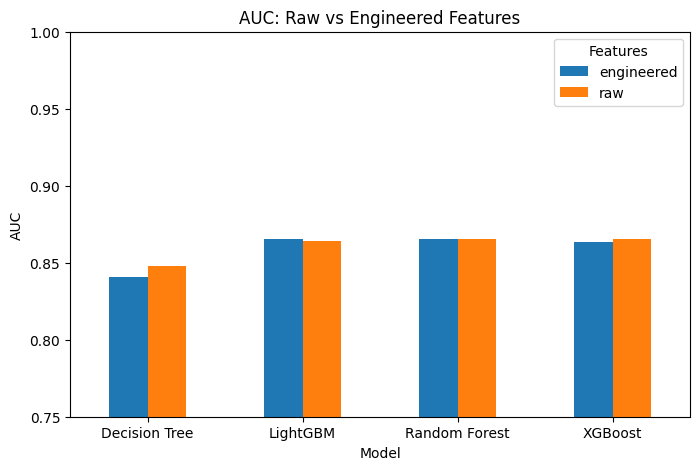

In [ ]:
pivot = results_df.pivot(index='Model', columns='Features', values='AUC')
pivot.plot(kind='bar', figsize=(8, 5))
plt.ylabel('AUC')
plt.ylim(0.75, 1.0)
plt.title('AUC: Raw vs Engineered Features')
plt.xticks(rotation=0)
plt.legend(title='Features')
plt.show()

# Part 3: Feature Selection, Tuning and Final Evaluation


Feature Importance and Feature Selection

armor_diff      48.95
health_diff      3.52
ct_armor         3.51
alive_diff       3.30
time_left        3.27
ct_money         3.00
t_money          2.81
money_diff       2.39
bomb_planted     2.17
rifle_diff       2.12
t_armor          2.07
ct_score         1.62
score_diff       1.49
t_score          1.28
helmet_diff      1.26
dtype: float64
Top   3 features -> AUC: 0.8463
Top   5 features -> AUC: 0.8526
Top  10 features -> AUC: 0.8644
Top  15 features -> AUC: 0.8652
Top  20 features -> AUC: 0.8656
Top  30 features -> AUC: 0.8662
Top  50 features -> AUC: 0.8650
Top 119 features -> AUC: 0.8654


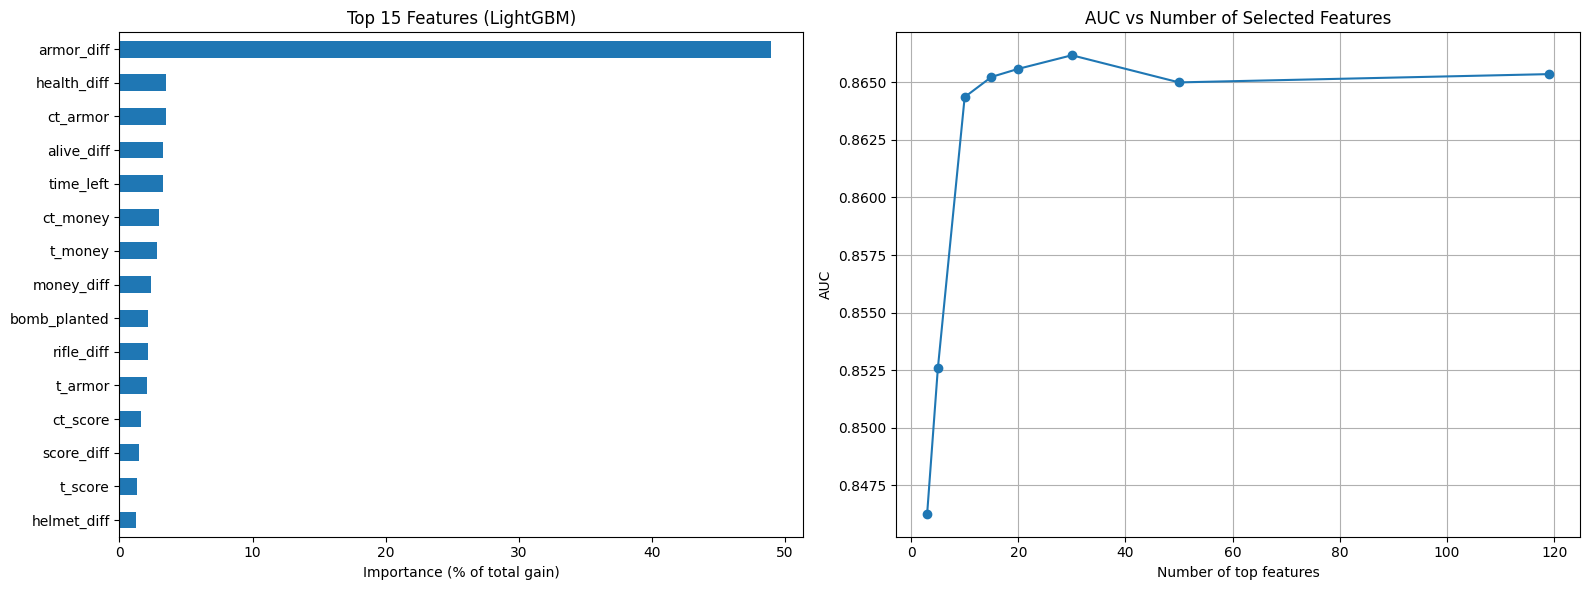

In [ ]:
# 1. Feature importance (train data only)
lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.1,
                      n_jobs=-1, random_state=RANDOM_STATE, verbose=-1)
lgbm.fit(df_model.loc[train_idx, all_cols], y_train)

imp = pd.Series(lgbm.booster_.feature_importance(importance_type='gain'),
                index=all_cols).sort_values(ascending=False)
imp_pct = (imp / imp.sum() * 100).round(2)
print(imp_pct.head(15))

# 2. AUC vs top-k features
ranked = imp.index.tolist()
ks = [3, 5, 10, 15, 20, 30, 50, len(all_cols)]
auc_k = []

for k in ks:
    cols_k = ranked[:k]
    m = LGBMClassifier(n_estimators=300, learning_rate=0.1,
                       n_jobs=-1, random_state=RANDOM_STATE, verbose=-1)
    m.fit(df_model.loc[train_idx, cols_k], y_train)
    prob = m.predict_proba(df_model.loc[test_idx, cols_k])[:, 1]
    auc_k.append(roc_auc_score(y_test, prob))
    print(f"Top {k:3d} features -> AUC: {auc_k[-1]:.4f}")

# 3. Both graphs side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: top 15 feature importance
imp_pct.head(15).sort_values().plot(kind='barh', ax=axes[0])
axes[0].set_xlabel('Importance (% of total gain)')
axes[0].set_title('Top 15 Features (LightGBM)')

# Right: AUC vs number of features
axes[1].plot(ks, auc_k, marker='o')
axes[1].set_xlabel('Number of top features')
axes[1].set_ylabel('AUC')
axes[1].set_title('AUC vs Number of Selected Features')
axes[1].grid(True)

plt.tight_layout()
plt.show()

Hyperparameter Tuning (LightGBM)

In [ ]:
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import confusion_matrix

SELECTED = ranked[:15]
X_train_sel = df_model.loc[train_idx, SELECTED]
X_test_sel  = df_model.loc[test_idx, SELECTED]
groups_train = df_model.loc[train_idx, 'round_id']

# Default model (tuning er age) baseline hishebe
default_model = LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
default_model.fit(X_train_sel, y_train)
default_prob = default_model.predict_proba(X_test_sel)[:, 1]
print(f"Default LightGBM (top 15): AUC = {roc_auc_score(y_test, default_prob):.4f}")

# Grid search
param_grid = {
    'num_leaves':       [31, 63],
    'learning_rate':    [0.05, 0.1],
    'n_estimators':     [200, 400],
    'min_child_samples': [20, 50],
}

grid = GridSearchCV(
    LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
    param_grid,
    scoring='roc_auc',
    cv=GroupKFold(n_splits=5),
    n_jobs=1,
    verbose=1
)
grid.fit(X_train_sel, y_train, groups=groups_train)

print("Best params:", grid.best_params_)
print(f"Best CV AUC: {grid.best_score_:.4f}")

Default LightGBM (top 15): AUC = 0.8664
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best params: {'learning_rate': 0.05, 'min_child_samples': 50, 'n_estimators': 200, 'num_leaves': 31}
Best CV AUC: 0.8686


Final Evaluation

Tuned LightGBM (top 15)
Accuracy:    0.7591
AUC:         0.8669
Sensitivity: 0.7936 (CT win)
Specificity: 0.7272 (T win)


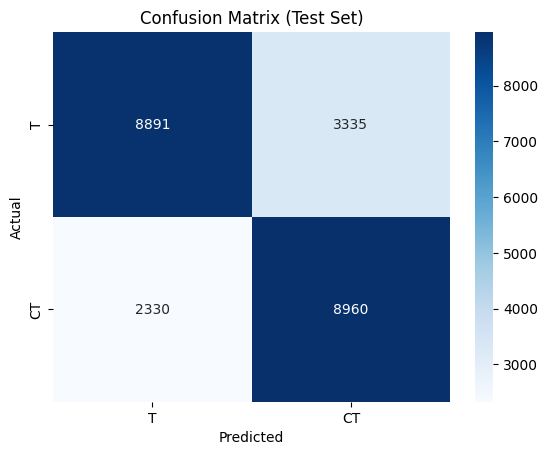

In [ ]:
best = grid.best_estimator_
prob = best.predict_proba(X_test_sel)[:, 1]
pred = (prob >= 0.5).astype(int)

acc = accuracy_score(y_test, pred)
auc = roc_auc_score(y_test, prob)

tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
sensitivity = tp / (tp + fn)      # CT jitle, model koto bar shothik bolche
specificity = tn / (tn + fp)      # T jitle, model koto bar shothik bolche

print(f"Tuned LightGBM (top 15)")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC:         {auc:.4f}")
print(f"Sensitivity: {sensitivity:.4f} (CT win)")
print(f"Specificity: {specificity:.4f} (T win)")

cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['T', 'CT'], yticklabels=['T', 'CT'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Test Set)')
plt.show()

# Part 4: Statistical Testing, Ensemble and Prediction


Cross-Validation of All Models

In [ ]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from scipy import stats

models9 = {
    'LogReg':        make_pipeline(StandardScaler(),
                                   LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=100, n_jobs=-1,
                                            random_state=RANDOM_STATE),
    'XGBoost':       XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=6,
                                   eval_metric='logloss', n_jobs=-1,
                                   random_state=RANDOM_STATE),
    'LightGBM':      LGBMClassifier(**grid.best_params_, random_state=RANDOM_STATE,
                                    n_jobs=-1, verbose=-1),
}

# 1. Fold-wise AUC (same GroupKFold folds shob model er jonno)
gkf = GroupKFold(n_splits=5)
folds = list(gkf.split(X_train_sel, y_train, groups=groups_train))

cv_auc = {name: [] for name in models9}
for name, model in models9.items():
    for tr, va in folds:
        m = clone(model)
        m.fit(X_train_sel.iloc[tr], y_train.iloc[tr])
        p = m.predict_proba(X_train_sel.iloc[va])[:, 1]
        cv_auc[name].append(roc_auc_score(y_train.iloc[va], p))
    print(f"{name:15s} CV AUC: {np.mean(cv_auc[name]):.4f} ± {np.std(cv_auc[name]):.4f}")

cv_df = pd.DataFrame(cv_auc)

LogReg          CV AUC: 0.8506 ± 0.0039
Decision Tree   CV AUC: 0.8420 ± 0.0038
Random Forest   CV AUC: 0.8587 ± 0.0034
XGBoost         CV AUC: 0.8675 ± 0.0041
LightGBM        CV AUC: 0.8686 ± 0.0040


Box Plot, ANOVA and Post-hoc Tests

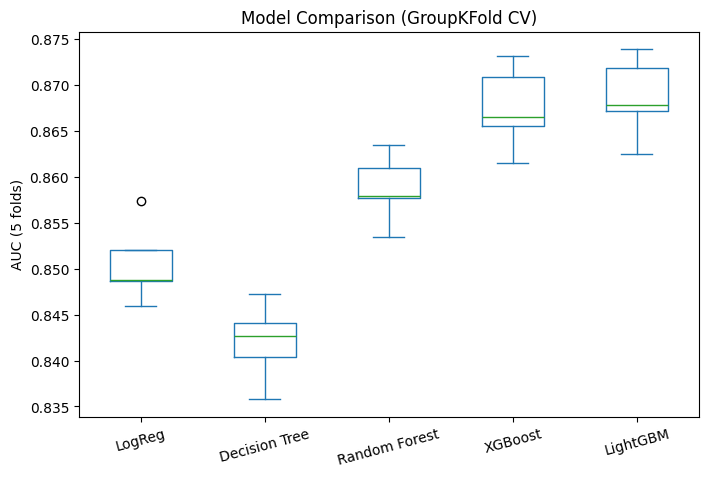

ANOVA: F = 34.60, p = 1.003e-08
Bonferroni alpha = 0.0050
LogReg         vs Decision Tree  p = 0.0010  significant
LogReg         vs Random Forest  p = 0.0002  significant
LogReg         vs XGBoost        p = 0.0000  significant
LogReg         vs LightGBM       p = 0.0000  significant
Decision Tree  vs Random Forest  p = 0.0000  significant
Decision Tree  vs XGBoost        p = 0.0000  significant
Decision Tree  vs LightGBM       p = 0.0000  significant
Random Forest  vs XGBoost        p = 0.0000  significant
Random Forest  vs LightGBM       p = 0.0000  significant
XGBoost        vs LightGBM       p = 0.0018  significant


In [ ]:
# 2. Box plot
cv_df.plot(kind='box', figsize=(8, 5))
plt.ylabel('AUC (5 folds)')
plt.title('Model Comparison (GroupKFold CV)')
plt.xticks(rotation=15)
plt.show()

# 3. One-way ANOVA
f_stat, p_val = stats.f_oneway(*[cv_df[c] for c in cv_df.columns])
print(f"ANOVA: F = {f_stat:.2f}, p = {p_val:.4g}")

# 4. Post-hoc paired t-tests (same folds, tai paired)
names = list(cv_df.columns)
pairs = [(a, b) for i, a in enumerate(names) for b in names[i+1:]]
alpha = 0.05 / len(pairs)     # Bonferroni correction
print(f"Bonferroni alpha = {alpha:.4f}")
for a, b in pairs:
    t, p = stats.ttest_rel(cv_df[a], cv_df[b])
    flag = "significant" if p < alpha else "-"
    print(f"{a:14s} vs {b:14s} p = {p:.4f}  {flag}")

Weighted Ensemble

In [ ]:
# 5. Weighted ensemble: weight = mean CV AUC
weights = cv_df.mean()
weights = weights / weights.sum()
print(weights.round(4))

# Full train e fit, test e predict
test_probs = {}
for name, model in models9.items():
    m = clone(model)
    m.fit(X_train_sel, y_train)
    test_probs[name] = m.predict_proba(X_test_sel)[:, 1]
    print(f"{name:15s} Test AUC: {roc_auc_score(y_test, test_probs[name]):.4f}")

ens_prob = sum(weights[n] * test_probs[n] for n in models9)
ens_pred = (ens_prob >= 0.5).astype(int)
print(f"\nWeighted Ensemble  Accuracy: {accuracy_score(y_test, ens_pred):.4f} "
      f"| AUC: {roc_auc_score(y_test, ens_prob):.4f}")

LogReg           0.1984
Decision Tree    0.1964
Random Forest    0.2003
XGBoost          0.2023
LightGBM         0.2026
dtype: float64
LogReg          Test AUC: 0.8484
Decision Tree   Test AUC: 0.8433
Random Forest   Test AUC: 0.8598
XGBoost         Test AUC: 0.8659
LightGBM        Test AUC: 0.8669

Weighted Ensemble  Accuracy: 0.7645 | AUC: 0.8669


Summary Table and ROC Curves

            Model  CV AUC  Test AUC  Test Accuracy
         LightGBM  0.8686    0.8669         0.7591
Weighted Ensemble     NaN    0.8669         0.7645
          XGBoost  0.8675    0.8659         0.7608
    Random Forest  0.8587    0.8598         0.7589
           LogReg  0.8506    0.8484         0.7530
    Decision Tree  0.8420    0.8433         0.7477


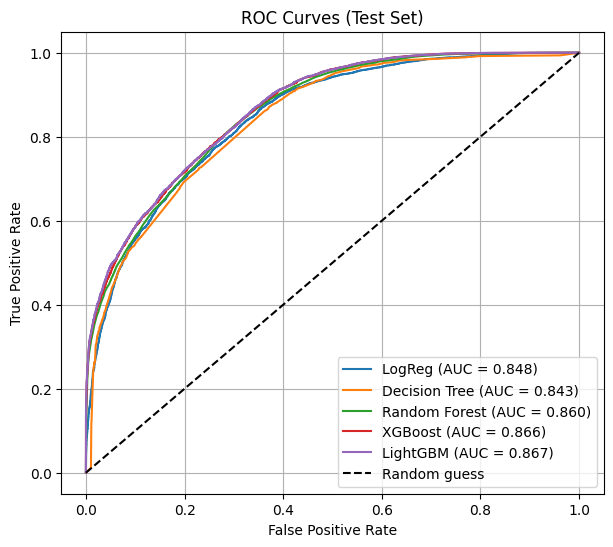

In [ ]:
from sklearn.metrics import roc_curve

# 1. Final summary table
rows = []
for name, p in test_probs.items():
    rows.append({'Model': name,
                 'CV AUC': round(cv_df[name].mean(), 4),
                 'Test AUC': round(roc_auc_score(y_test, p), 4),
                 'Test Accuracy': round(accuracy_score(y_test, (p >= 0.5).astype(int)), 4)})
rows.append({'Model': 'Weighted Ensemble', 'CV AUC': np.nan,
             'Test AUC': round(roc_auc_score(y_test, ens_prob), 4),
             'Test Accuracy': round(accuracy_score(y_test, ens_pred), 4)})
summary_df = pd.DataFrame(rows).sort_values('Test AUC', ascending=False)
print(summary_df.to_string(index=False))

# 2. ROC curves
plt.figure(figsize=(7, 6))
for name, p in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves (Test Set)')
plt.legend()
plt.grid(True)
plt.show()

Prediction Function

In [ ]:
def predict_round(snap):
    """snap: dict of raw snapshot values. Returns CT win probability."""
    f = dict(snap)
    f['alive_diff']  = f['ct_players_alive'] - f['t_players_alive']
    f['health_diff'] = f['ct_health'] - f['t_health']
    f['armor_diff']  = f['ct_armor'] - f['t_armor']
    f['money_diff']  = f['ct_money'] - f['t_money']
    f['helmet_diff'] = f['ct_helmets'] - f['t_helmets']
    f['score_diff']  = f['ct_score'] - f['t_score']
    f['rifle_diff']  = f['ct_rifles'] - f['t_rifles']
    row = pd.DataFrame([f])[SELECTED]
    p_ct = best.predict_proba(row)[0, 1]
    winner = 'CT' if p_ct >= 0.5 else 'T'
    print(f"CT win probability: {p_ct:.1%} -> Predicted winner: {winner}")
    return p_ct

# Example 1: CT agey (5 vs 3 alive, bomb plant hoyni)
_ = predict_round({'ct_players_alive': 5, 't_players_alive': 3, 'ct_health': 450, 't_health': 220,
                   'ct_armor': 480, 't_armor': 200, 'ct_money': 6000, 't_money': 3000,
                   'ct_helmets': 5, 't_helmets': 2, 'ct_score': 4, 't_score': 3,
                   'ct_rifles': 4, 't_rifles': 2, 'time_left': 80, 'bomb_planted': 0})

# Example 2: T agey, bomb planted
_ = predict_round({'ct_players_alive': 2, 't_players_alive': 4, 'ct_health': 150, 't_health': 380,
                   'ct_armor': 100, 't_armor': 350, 'ct_money': 2000, 't_money': 5000,
                   'ct_helmets': 1, 't_helmets': 4, 'ct_score': 3, 't_score': 5,
                   'ct_rifles': 1, 't_rifles': 3, 'time_left': 30, 'bomb_planted': 1})

CT win probability: 93.9% -> Predicted winner: CT
CT win probability: 0.3% -> Predicted winner: T


# Part 5: Interactive Round Predictor App
The tuned LightGBM model is saved and wrapped in a Gradio web app. The user enters a round snapshot, the app validates it, and then shows the predicted winner with probabilities.

### Install Gradio

In [ ]:
!pip install -q gradio

### Save the Model

In [ ]:
import joblib

# Save the tuned model together with the exact feature list used for training
joblib.dump({'model': best, 'features': SELECTED}, 'csgo_model.joblib')
print("Model saved to csgo_model.joblib")
print("Features used by the model:", SELECTED)

Model saved to csgo_model.joblib
Features used by the model: ['armor_diff', 'health_diff', 'ct_armor', 'alive_diff', 'time_left', 'ct_money', 't_money', 'money_diff', 'bomb_planted', 'rifle_diff', 't_armor', 'ct_score', 'score_diff', 't_score', 'helmet_diff']


### Input Validation

In [ ]:
import math

COUNT_FIELDS = ["CT players alive", "T players alive", "CT helmets", "T helmets",
                "CT rifles", "T rifles", "CT score", "T score"]

def _is_number(x):
    return isinstance(x, (int, float)) and not isinstance(x, bool) and not math.isnan(x)

def validate_snapshot(ct_alive, t_alive, ct_health, t_health, ct_armor, t_armor,
                      ct_money, t_money, ct_helmets, t_helmets, ct_rifles, t_rifles,
                      ct_score, t_score, time_left, bomb_planted):
    """Check a round snapshot for impossible values. Returns a list of error messages (empty = valid)."""
    fields = {
        "CT players alive": ct_alive, "T players alive": t_alive,
        "CT health": ct_health, "T health": t_health,
        "CT armor": ct_armor, "T armor": t_armor,
        "CT money": ct_money, "T money": t_money,
        "CT helmets": ct_helmets, "T helmets": t_helmets,
        "CT rifles": ct_rifles, "T rifles": t_rifles,
        "CT score": ct_score, "T score": t_score,
        "Time left": time_left,
    }
    errors = []

    # 1. Every field must be present and numeric
    for name, value in fields.items():
        if value is None or not _is_number(value):
            errors.append(f"{name} is required and must be a number.")
    if bomb_planted not in ("Yes", "No"):
        errors.append("Bomb planted must be either Yes or No.")
    if errors:
        return errors

    # 2. No negative values
    for name, value in fields.items():
        if value < 0:
            errors.append(f"{name} cannot be negative.")

    # 3. Count fields must be whole numbers
    for name in COUNT_FIELDS:
        if not float(fields[name]).is_integer():
            errors.append(f"{name} must be a whole number.")
    if errors:
        return errors

    # 4. Players alive: 0 to 5 per team, and the round cannot be already over for both teams
    for team, alive in (("CT", ct_alive), ("T", t_alive)):
        if alive > 5:
            errors.append(f"{team} players alive cannot be more than 5.")
    if ct_alive == 0 and t_alive == 0:
        errors.append("Both teams have 0 players alive, so this round is already over.")
    if errors:
        return errors

    # 5. Health and armor depend on how many players are alive (max 100 each)
    for team, alive, health, armor in (("CT", ct_alive, ct_health, ct_armor),
                                       ("T", t_alive, t_health, t_armor)):
        if alive == 0:
            if health != 0:
                errors.append(f"{team} has 0 players alive, so {team} health must be 0.")
            if armor != 0:
                errors.append(f"{team} has 0 players alive, so {team} armor must be 0.")
        else:
            if health < alive:
                errors.append(f"{team} health must be at least {int(alive)} because {int(alive)} player(s) are alive (minimum 1 each).")
            if health > 100 * alive:
                errors.append(f"{team} health cannot exceed {int(100 * alive)} with {int(alive)} player(s) alive.")
            if armor > 100 * alive:
                errors.append(f"{team} armor cannot exceed {int(100 * alive)} with {int(alive)} player(s) alive.")

    # 6. Helmets and rifles cannot exceed the number of living players
    for team, alive, helmets, rifles in (("CT", ct_alive, ct_helmets, ct_rifles),
                                         ("T", t_alive, t_helmets, t_rifles)):
        if helmets > alive:
            errors.append(f"{team} helmets ({int(helmets)}) cannot exceed {team} players alive ({int(alive)}).")
        if rifles > alive:
            errors.append(f"{team} rifles ({int(rifles)}) cannot exceed {team} players alive ({int(alive)}).")

    # 7. Money: a team of 5 players can hold at most 5 x 16,000
    for team, money in (("CT", ct_money), ("T", t_money)):
        if money > 80000:
            errors.append(f"{team} money cannot exceed 80,000 (5 players x 16,000).")

    # 8. Score range (includes overtime rounds)
    for team, score in (("CT", ct_score), ("T", t_score)):
        if score > 30:
            errors.append(f"{team} score must be between 0 and 30.")

    # 9. Time left depends on the bomb state
    if bomb_planted == "Yes":
        if time_left > 40:
            errors.append("After the bomb is planted, time left cannot exceed 40 seconds.")
    elif time_left > 175:
        errors.append("Time left cannot exceed 175 seconds before the bomb is planted.")

    return errors

### Validation Tests

In [ ]:
# Quick tests for the validation function
valid = dict(ct_alive=5, t_alive=3, ct_health=450, t_health=220, ct_armor=480, t_armor=200,
             ct_money=6000, t_money=3000, ct_helmets=5, t_helmets=2, ct_rifles=4, t_rifles=2,
             ct_score=4, t_score=3, time_left=80, bomb_planted="No")

def check(**changes):
    return validate_snapshot(**{**valid, **changes})

assert check() == []                                              # valid snapshot
assert check(ct_health=-10)                                       # negative value
assert check(ct_alive=6)                                          # more than 5 players
assert check(ct_alive=0, t_alive=0, ct_health=0, t_health=0,
             ct_armor=0, t_armor=0, ct_helmets=0, t_helmets=0,
             ct_rifles=0, t_rifles=0)                             # round already over
assert check(t_alive=3, t_health=400)                             # health above 100 per player
assert check(t_alive=2, t_health=1)                               # health below 1 per player
assert check(t_helmets=4)                                         # more helmets than players
assert check(ct_rifles=6, ct_alive=5)                             # more rifles than players
assert check(ct_money=90000)                                      # unrealistic money
assert check(bomb_planted="Yes", time_left=100)                   # timer longer than bomb timer
assert check(ct_score=2.5)                                        # score not a whole number
assert check(ct_money=None)                                       # missing value
assert check(bomb_planted="Maybe")                                # invalid choice
print("All validation tests passed.")

All validation tests passed.


### Build and Launch the App

In [ ]:
import gradio as gr
import pandas as pd

# Load the saved model (the app only needs this file, not the training data)
artifact = joblib.load('csgo_model.joblib')
app_model = artifact['model']
app_features = artifact['features']

def build_features(ct_alive, t_alive, ct_health, t_health, ct_armor, t_armor,
                   ct_money, t_money, ct_helmets, t_helmets, ct_rifles, t_rifles,
                   ct_score, t_score, time_left, bomb_planted):
    """Turn the raw inputs into the exact feature row the model was trained on."""
    f = {
        'ct_players_alive': ct_alive, 't_players_alive': t_alive,
        'ct_health': ct_health, 't_health': t_health,
        'ct_armor': ct_armor, 't_armor': t_armor,
        'ct_money': ct_money, 't_money': t_money,
        'ct_helmets': ct_helmets, 't_helmets': t_helmets,
        'ct_rifles': ct_rifles, 't_rifles': t_rifles,
        'ct_score': ct_score, 't_score': t_score,
        'time_left': time_left,
        'bomb_planted': 1 if bomb_planted == "Yes" else 0,
    }
    f['alive_diff']  = ct_alive - t_alive
    f['health_diff'] = ct_health - t_health
    f['armor_diff']  = ct_armor - t_armor
    f['money_diff']  = ct_money - t_money
    f['helmet_diff'] = ct_helmets - t_helmets
    f['score_diff']  = ct_score - t_score
    f['rifle_diff']  = ct_rifles - t_rifles
    f['ct_avg_health'] = ct_health / ct_alive if ct_alive > 0 else 0
    f['t_avg_health']  = t_health / t_alive if t_alive > 0 else 0
    return pd.DataFrame([f])[app_features], f

def predict_snapshot(*inputs):
    errors = validate_snapshot(*inputs)
    if errors:
        raise gr.Error("Invalid input:\n" + "\n".join("- " + e for e in errors))

    row, f = build_features(*inputs)
    p_ct = float(app_model.predict_proba(row)[0, 1])
    p_t = 1 - p_ct
    winner = "CT" if p_ct >= 0.5 else "T"
    margin = max(p_ct, p_t)
    if margin >= 0.80:
        confidence = "Strong favourite"
    elif margin >= 0.60:
        confidence = "Moderate favourite"
    else:
        confidence = "Too close to call"

    summary = (
        f"### Predicted winner: **{winner}**  ({confidence})\n\n"
        f"| Factor | CT minus T |\n|---|---|\n"
        f"| Players alive | {f['alive_diff']:+.0f} |\n"
        f"| Total health | {f['health_diff']:+.0f} |\n"
        f"| Total armor | {f['armor_diff']:+.0f} |\n"
        f"| Money | {f['money_diff']:+,.0f} |\n"
        f"| Rifles | {f['rifle_diff']:+.0f} |\n"
        f"| Bomb planted | {bool(f['bomb_planted'])} |"
    )
    return {"CT wins": p_ct, "T wins": p_t}, summary

with gr.Blocks(title="CS:GO Round Winner Predictor") as demo:
    gr.Markdown("# CT or T? CS:GO Round Winner Predictor\n"
                "Enter a snapshot of the current round and the model will predict which team wins.")
    with gr.Accordion("How to fill the inputs (valid ranges)", open=True):
        gr.Markdown(
            "| Field | Meaning | Valid range |\n"
            "|---|---|---|\n"
            "| Players alive | Living players in the team | 0 to 5 |\n"
            "| Total health | Sum of health of all living players | 1 to 100 per living player |\n"
            "| Total armor | Sum of armor of all living players | 0 to 100 per living player |\n"
            "| Total money | Combined money of the whole team | 0 to 80,000 |\n"
            "| Helmets | Living players wearing a helmet | 0 up to players alive |\n"
            "| Rifles | Living players holding a rifle (AK-47, M4, AUG, SG 553, FAMAS, Galil) | 0 up to players alive |\n"
            "| Score | Rounds the team has already won | 0 to 30 |\n"
            "| Time left | Seconds left in the round | 0 to 175 (0 to 40 after the bomb is planted) |\n\n"
            "**Example:** 4 CT players alive, all at full health and full armor, means total health = 400 and total armor = 400."
        )
    with gr.Row():
        with gr.Column():
            gr.Markdown("### CT team (defenders)")
            ct_alive   = gr.Number(label="CT players alive", value=5, precision=0,
                                 info="Whole number from 0 to 5")
            ct_health  = gr.Number(label="CT total health", value=450,
                                 info="Sum of health of living CT players: 1 to 100 per player (3 alive = 3 to 300)")
            ct_armor   = gr.Number(label="CT total armor", value=480,
                                 info="Sum of armor of living CT players: 0 to 100 per player (3 alive = 0 to 300)")
            ct_money   = gr.Number(label="CT total money ($)", value=6000,
                                 info="Combined team money: 0 to 80,000 (about 4,000 at the start of a match)")
            ct_helmets = gr.Number(label="CT helmets", value=5, precision=0,
                                 info="Living CT players wearing a helmet: 0 up to CT players alive")
            ct_rifles  = gr.Number(label="CT rifles", value=4, precision=0,
                                 info="Living CT players holding a rifle: 0 up to CT players alive")
            ct_score   = gr.Number(label="CT score (rounds won)", value=4, precision=0,
                                 info="Rounds already won by CT: 0 to 30")
        with gr.Column():
            gr.Markdown("### T team (attackers)")
            t_alive   = gr.Number(label="T players alive", value=3, precision=0,
                                info="Whole number from 0 to 5")
            t_health  = gr.Number(label="T total health", value=220,
                                info="Sum of health of living T players: 1 to 100 per player (3 alive = 3 to 300)")
            t_armor   = gr.Number(label="T total armor", value=200,
                                info="Sum of armor of living T players: 0 to 100 per player (3 alive = 0 to 300)")
            t_money   = gr.Number(label="T total money ($)", value=3000,
                                info="Combined team money: 0 to 80,000 (about 4,000 at the start of a match)")
            t_helmets = gr.Number(label="T helmets", value=2, precision=0,
                                info="Living T players wearing a helmet: 0 up to T players alive")
            t_rifles  = gr.Number(label="T rifles", value=2, precision=0,
                                info="Living T players holding a rifle: 0 up to T players alive")
            t_score   = gr.Number(label="T score (rounds won)", value=3, precision=0,
                                info="Rounds already won by T: 0 to 30")
    with gr.Row():
        time_left = gr.Number(label="Time left (seconds)", value=80,
                              info="0 to 175 before the bomb is planted, 0 to 40 after it is planted")
        bomb_planted = gr.Radio(["No", "Yes"], label="Bomb planted?", value="No")

    predict_btn = gr.Button("Predict Winner", variant="primary")
    out_label = gr.Label(label="Win probability", num_top_classes=2)
    out_text = gr.Markdown()

    inputs = [ct_alive, t_alive, ct_health, t_health, ct_armor, t_armor,
              ct_money, t_money, ct_helmets, t_helmets, ct_rifles, t_rifles,
              ct_score, t_score, time_left, bomb_planted]
    predict_btn.click(predict_snapshot, inputs=inputs, outputs=[out_label, out_text])

    gr.Examples(
        examples=[
            [5, 3, 450, 220, 480, 200, 6000, 3000, 5, 2, 4, 2, 4, 3, 80, "No"],
            [2, 4, 150, 380, 100, 350, 2000, 5000, 1, 4, 1, 3, 3, 5, 30, "Yes"],
            [5, 5, 500, 500, 400, 400, 9000, 9000, 4, 4, 3, 3, 7, 7, 100, "No"],
        ],
        inputs=inputs,
        label="Example snapshots (CT ahead, T ahead with bomb planted, even round)",
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://335ec38dfbac090004.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Conclusion

We predicted CS:GO round winners from 117k de-duplicated snapshots (about 23.5k rounds), using round-level grouped splits to prevent leakage. LightGBM, tuned with GroupKFold, reached a test AUC of 0.867 and accuracy of 0.759, with XGBoost nearly identical. Armor difference was the single most important feature, and 10 to 15 features matched the performance of all 119. Hand-crafted difference features and a weighted ensemble gave no meaningful AUC gain, suggesting the raw snapshot already contains most of the signal.

**Limitations.** Round IDs were reconstructed from the time_left column. The cross-validation p-values are optimistic because of only five folds. The grid search optimum sat at the edge of the grid. Snapshots taken early in a round are inherently uncertain, which limits achievable accuracy.